# <b> Felis Taxonomy Image Classification </b>
### <b>Name</b>: <i>Harichandhana.P</i>
### <b>School</b>: <i>CDS</i>


In [ ]:
# import system libs
import os
import time
import pathlib

import glob
import PIL
from PIL import Image, ImageEnhance

# import data handling tools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras

print ('modules loaded')

modules loaded


a. Total number of images in the dataset - 519
<br>b. Number of images present per class - [86, 42, 79, 72, 91, 64, 85]
<br>c. Total number of images used for training and testing: <br> &nbsp;&nbsp;&nbsp;&nbsp;training files- 389 <br> &nbsp;&nbsp;&nbsp;&nbsp;testing files- 130

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
classes = os.listdir("/content/drive/MyDrive/Datasets/Felis_Taxonomy")
num_classes = len(classes)
print(num_classes)
print(classes)

7
['chinese-mountain-cat', 'african-wildcat', 'sand-cat', 'european-wildcat', 'blackfoot-cat', 'domestic-cat', 'jungle-cat']


In [ ]:
# Create lists to store file paths and labels
file_paths = []
labels = []
class_files_count=[]
total_count=0
# Iterate through each class folder
for class_index, class_name in enumerate(classes):
    class_count=0
    class_folder = os.path.join("/content/drive/MyDrive/Datasets/Felis_Taxonomy", class_name)
    class_files = os.listdir(class_folder)

    # Append file paths and labels for each image in the class folder
    for file in class_files:
        file_paths.append(os.path.join(class_folder, file))
        total_count+=1
        class_count+=1
        labels.append(class_name)
    class_files_count.append(class_count)

In [ ]:
print(total_count)
print(class_files_count)

519
[42, 91, 72, 85, 79, 64, 86]


In [ ]:
X = []
for fName in file_paths:

  # Prepare the dataset and populate X
  X_i = Image.open(fName)
  X_i = X_i.resize((299,299)) # To make them approriate to InceptionV3 model when using Transfer Learning
  X_i = np.array(X_i) / 255.0 # Normalize to range 0.0 to 1.0 (not stretching, only scaling)
  X.append(X_i)


In [ ]:
from sklearn.preprocessing import LabelEncoder
lEncoder = LabelEncoder()
y = lEncoder.fit_transform(labels)

print(set(y))
print(lEncoder.classes_)

X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

{0, 1, 2, 3, 4, 5, 6}
['african-wildcat' 'blackfoot-cat' 'chinese-mountain-cat' 'domestic-cat'
 'european-wildcat' 'jungle-cat' 'sand-cat']
(519, 299, 299, 3)
(519,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                    stratify=y, random_state=42)

print("X_train_shape: {}".format(X_train.shape))
print("X_test_shape: {}".format(X_test.shape))

X_train_shape: (389, 299, 299, 3)
X_test_shape: (130, 299, 299, 3)


In [ ]:
print(len(X_train))
print(len(X_test))

389
130


In [ ]:
mu = X_train.mean()
std = X_train.std()

X_train_std = (X_train-mu)/std
X_test_std = (X_test-mu)/std

In [ ]:
#Trasnfer learning
# Retrieve the InceptionV3 model from Keras

base_model = keras.applications.InceptionV3(
    include_top=False ,
    weights="imagenet",

)


87910968/87910968 [==============================] - 4s 0us/step


In [ ]:
# Freeze the weights - will not be updated during backpropagation
for layer in base_model.layers:
  layer.trainabe = False

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
# Adding classifier

global_pool = keras.layers.GlobalAveragePooling2D()(base_model.output)
x = BatchNormalization()(global_pool)  # Adding BatchNormalization layer
x = Dropout(0.25)(x)  # Adding Dropout layer with 25% drop rate
output_ = keras.layers.Dense(units=7, activation='softmax')(x)


model_TL = keras.models.Model(inputs=[base_model.input], outputs=[output_])


In [ ]:
model_TL.compile(loss='sparse_categorical_crossentropy',
                 optimizer='adam',
                 metrics=['accuracy'])

callbacks_TL = [
             keras.callbacks.ModelCheckpoint("bestTL.h5",
                                             monitor='val_accuracy',
                                             save_weights_only=True,
                                             save_best_only=True)]

history_TL = model_TL.fit(x = X_train_std, y = y_train, epochs=10,
                          validation_split=0.1, batch_size=32, callbacks=callbacks_TL)

Epoch 1/10
11/11 [==============================] - 37s 658ms/step - loss: 0.1588 - accuracy: 0.9543 - val_loss: 8.5690 - val_accuracy: 0.4872
Epoch 2/10
11/11 [==============================] - 5s 474ms/step - loss: 0.2028 - accuracy: 0.9457 - val_loss: 4.1281 - val_accuracy: 0.4872
Epoch 3/10
11/11 [==============================] - 6s 524ms/step - loss: 0.1901 - accuracy: 0.9486 - val_loss: 2.8827 - val_accuracy: 0.5641
Epoch 4/10
11/11 [==============================] - 5s 471ms/step - loss: 0.1112 - accuracy: 0.9571 - val_loss: 2.6606 - val_accuracy: 0.5641
Epoch 5/10
11/11 [==============================] - 6s 507ms/step - loss: 0.0499 - accuracy: 0.9886 - val_loss: 3.4620 - val_accuracy: 0.4359
Epoch 6/10
11/11 [==============================] - 5s 491ms/step - loss: 0.0479 - accuracy: 0.9829 - val_loss: 1.7851 - val_accuracy: 0.5641
Epoch 7/10
11/11 [==============================] - 6s 558ms/step - loss: 0.0365 - accuracy: 0.9914 - val_loss: 1.3389 - val_accuracy: 0.6923
Epoch

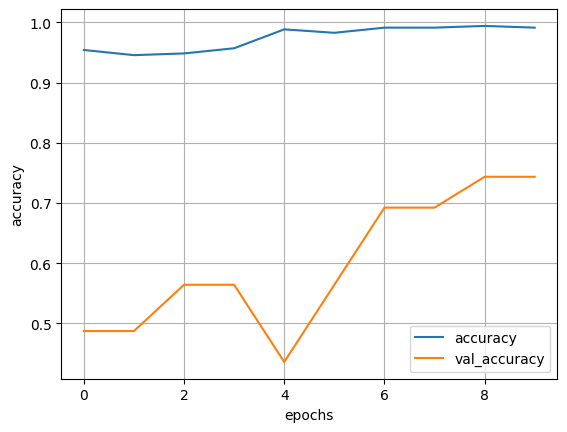

In [ ]:
keys = ['accuracy', 'val_accuracy']
progress = {k:v for k,v in history_TL.history.items() if k in keys}

import pandas as pd
pd.DataFrame(progress).plot()

plt.xlabel("epochs")
plt.ylabel("accuracy")

plt.grid(True)
plt.show()

In [ ]:
testLoss_TL, testAccuracy_TL = model_TL.evaluate(x = X_test_std, y = y_test)
print("Test-loss: %f, Test-accuracy: %f" % (testLoss_TL, testAccuracy_TL))

5/5 [==============================] - 1s 103ms/step - loss: 1.6937 - accuracy: 0.6308
Test-loss: 1.693716, Test-accuracy: 0.630769


In [ ]:
model_TL.load_weights("bestTL.h5")

testLoss_TL, testAccuracy_TL = model_TL.evaluate(x = X_test_std, y = y_test)

print("Test-loss: %f, Test-accuracy: %f" % (testLoss_TL, testAccuracy_TL))

5/5 [==============================] - 1s 99ms/step - loss: 1.7549 - accuracy: 0.6538
Test-loss: 1.754885, Test-accuracy: 0.653846


In [ ]:
# Saves the best model obtained
model_TL.save('/content/drive/MyDrive/Models/01_InceptionV3_TransferLearning_Best_Model.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
from numpy import save

save('/content/drive/MyDrive/Models/X_train_std.npy', X_train_std)
save('/content/drive/MyDrive/Models/X_test_std.npy', X_test_std)

save('/content/drive/MyDrive/Models/y_train.npy', y_train)
save('/content/drive/MyDrive/Models/y_test.npy', y_test)